# 02 — Data Cleaning
Input: `data/raw/uber_raw.csv` (from notebook 01). Output: `data/processed/uber_cleaned.csv`.

Every decision is logged in `log` and summarised in `reports/cleaning_report.md`.
No imputation statistics are computed here — imputation lives inside the preprocessing pipeline (fit on train only).

In [1]:
# --- Project setup (works locally and on Colab after cloning the repo) ---
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: D:\ML


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/raw/uber_raw.csv")

print(df.shape)
display(df.head())
df.info()

log = []                     # (step, rows_before, rows_after, reason)
summary = {"rows_before": len(df),
           "missing_before": int(df.isnull().sum().sum()),
           "duplicates_before": int(df.duplicated().sum())}

(693071, 57)


,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,1.544953e+09,9,16,12,2018-12-16 09:30:07,America/New_York,Haymarket Square,North Station,Lyft,...,0.1276,1544979600,39.89,1545012000,43.68,1544968800,33.73,1545012000,38.07,1544958000
1,4bd23055-6827-41c6-b23b-3c491f24e74d,1.543284e+09,2,27,11,2018-11-27 02:00:23,America/New_York,Haymarket Square,North Station,Lyft,...,0.1300,1543251600,40.49,1543233600,47.30,1543251600,36.20,1543291200,43.92,1543251600
2,981a3613-77af-4620-a42a-0c0866077d1e,1.543367e+09,1,28,11,2018-11-28 01:00:22,America/New_York,Haymarket Square,North Station,Lyft,...,0.1064,1543338000,35.36,1543377600,47.55,1543320000,31.04,1543377600,44.12,1543320000
3,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,1.543554e+09,4,30,11,2018-11-30 04:53:02,America/New_York,Haymarket Square,North Station,Lyft,...,0.0000,1543507200,34.67,1543550400,45.03,1543510800,30.30,1543550400,38.53,1543510800
4,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,1.543463e+09,3,29,11,2018-11-29 03:49:20,America/New_York,Haymarket Square,North Station,Lyft,...,0.0001,1543420800,33.10,1543402800,42.18,1543420800,29.11,1543392000,35.75,1543420800


<class 'pandas.DataFrame'>
RangeIndex: 693071 entries, 0 to 693070
Data columns (total 57 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           693071 non-null  str    
 1   timestamp                    693071 non-null  float64
 2   hour                         693071 non-null  int64  
 3   day                          693071 non-null  int64  
 4   month                        693071 non-null  int64  
 5   datetime                     693071 non-null  str    
 6   timezone                     693071 non-null  str    
 7   source                       693071 non-null  str    
 8   destination                  693071 non-null  str    
 9   cab_type                     693071 non-null  str    
 10  product_id                   693071 non-null  str    
 11  name                         693071 non-null  str    
 12  price                        637976 non-null  float64
 13  distance  

## 1. Missing values

In [3]:
missing = pd.DataFrame({"missing": df.isnull().sum(), "percent": df.isnull().mean() * 100})
display(missing[missing["missing"] > 0])
display(df[df["price"].isnull()].groupby(["cab_type", "name"]).size().rename("rows_with_missing_price"))

,missing,percent
price,55095,7.949402


cab_type  name
Uber      Taxi    55095
Name: rows_with_missing_price, dtype: int64

### Missing values BEFORE any filtering
Only **`price`** has missing values: **55,095 rows (7.95%)**. The table above shows that every one of them is an
**Uber Taxi** quote (`cab_type = Uber`, `name = Taxi`), because the API returned no price for taxis.

What we do with them:
- They are **not imputed**. `price` is a **leakage** column (price = base fare x surge), so it is never a model
  feature, and filling it in would only create fake values.
- The rows are **dropped** in step 2 below, because they are Uber rows and their surge target is not real
  (Uber surge is always 1.0). The rule removes all Uber rows, not only the ones with a missing price.
- The model can still receive missing **feature** values later, for example from the GUI. For that, the Pipeline
  contains `SimpleImputer`s (median for numeric, most frequent for categorical) that are fitted on training data only.
  Notebook 06 demonstrates this by injecting missing values into a copy of some training rows and showing the saved
  Pipeline still predicts.

In [4]:
missing_by_type = df.assign(price_missing=df["price"].isnull()).groupby("cab_type")["price_missing"].agg(["sum", "mean"])
missing_by_type["mean"] *= 100
display(missing_by_type.rename(columns={"sum": "missing prices", "mean": "% missing"}))

,missing prices,% missing
cab_type,,
Lyft,0,0.000000
Uber,55095,14.285788


## 2. Invalid target rows — keep Lyft only
Uber rows carry a constant `surge_multiplier = 1.0` that was never really observed (see notebook 01).
A row whose target is not a real measurement cannot be used for supervised learning → removed.

In [5]:
before = len(df)
df = df[df["cab_type"] == "Lyft"].copy()
log.append(("Remove Uber rows (target not recorded)", before, len(df), "surge_multiplier constant 1.0 for all Uber rows"))

before = len(df)
df = df.dropna(subset=["surge_multiplier"])
log.append(("Drop rows with missing target", before, len(df), "cannot train on missing target"))
print(df.shape)
print("Missing after filtering:", df.isnull().sum().sum())

(307408, 57)
Missing after filtering: 0


## 3. Duplicates

In [6]:
print("Duplicates Before:")
print(df.duplicated().sum())

before = len(df)
df = df.drop_duplicates()
log.append(("Drop exact duplicate rows", before, len(df), "identical records"))

print("Duplicates After:")
print(df.duplicated().sum())

print("Duplicate ids:", df["id"].duplicated().sum())

Duplicates Before:


0


Duplicates After:


0


Duplicate ids: 0


### Partial duplicates
Several rows share the same `timestamp`, `source`, `destination` and `name`. Are they repeated trips?

In [7]:
key = ["timestamp", "source", "destination", "name"]
part = df[df.duplicated(key, keep=False)].sort_values(key)
print("Rows sharing timestamp+route+product:", len(part))
display(part[key + ["id", "price", "distance", "surge_multiplier"]].head(6))

no_id = [c for c in df.columns if c != "id"]
print("Rows identical in every column except id:", df.duplicated(no_id).sum())

Rows sharing timestamp+route+product: 11091


,timestamp,source,destination,name,id,price,distance,surge_multiplier
80294,1.543208e+09,West End,North End,Lux,3baf90ef-1783-41c5-90f4-d9726b36a5c8,13.5,1.08,1.0
647752,1.543208e+09,West End,North End,Lux,cb7d3863-64de-413f-8602-288320fdd1ef,13.5,1.06,1.0
557965,1.543210e+09,Beacon Hill,North End,Lyft,29abbde2-fb4e-4a5c-a29e-fdbf1b555b9f,9.0,2.03,1.0
585062,1.543210e+09,Beacon Hill,North End,Lyft,dcf00706-0791-49a0-ac32-4d6714b04f47,7.0,1.76,1.0
231542,1.543213e+09,Back Bay,South Station,Lux,ea557d72-a3f7-49b8-ad49-f982866b7513,13.5,1.49,1.0
304736,1.543213e+09,Back Bay,South Station,Lux,34fdd2d4-2a09-43bc-ac2c-be6cf9b79c63,16.5,1.34,1.0


Rows identical in every column except id: 156


- Rows with the same time, route and product but a **different distance or price** are separate quotes
  (for example, different exact pickup points). They are kept.
- Rows that are identical in **every column except `id`** are the same quote recorded twice with a new id.
  They are removed.
- Rows with the same route but a different product are not duplicates, because one request returns one row per product.

In [8]:
before = len(df)
df = df.drop_duplicates(subset=no_id)
log.append(("Drop duplicates ignoring id", before, len(df), "same quote stored twice under different ids"))
print(before, "->", len(df))

307408 -> 307252


## 4. Data types

In [9]:
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
invalid_dates = df["datetime"].isnull().sum()
print("Invalid datetimes:", invalid_dates)

for col in ["distance", "surge_multiplier", "price"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["source", "destination", "name", "short_summary"]:
    df[col] = df[col].astype(str).str.strip()

print(df[["datetime", "distance", "surge_multiplier", "source", "short_summary"]].dtypes)
print(df["short_summary"].unique())

Invalid datetimes: 0


datetime            datetime64[us]
distance                   float64
surge_multiplier           float64
source                         str
short_summary                  str
dtype: object
<ArrowStringArray>
[   'Mostly Cloudy',             'Rain',            'Clear',
    'Partly Cloudy',         'Overcast',       'Light Rain',
            'Foggy', 'Possible Drizzle',          'Drizzle']
Length: 9, dtype: str


`short_summary` had leading/trailing spaces (`' Mostly Cloudy '`) → stripped.

## 5. Validation of impossible values

In [10]:
checks = {
    "distance <= 0": (df["distance"] <= 0).sum(),
    "surge_multiplier <= 0": (df["surge_multiplier"] <= 0).sum(),
    "humidity outside [0,1]": (~df["humidity"].between(0, 1)).sum(),
    "cloudCover outside [0,1]": (~df["cloudCover"].between(0, 1)).sum(),
    "latitude outside Boston area (42.2–42.5)": (~df["latitude"].between(42.2, 42.5)).sum(),
    "longitude outside Boston area (-71.2–-70.9)": (~df["longitude"].between(-71.2, -70.9)).sum(),
    "datetime outside collection period": (~df["datetime"].between("2018-11-01", "2018-12-31")).sum(),
    "source == destination": (df["source"] == df["destination"]).sum(),
}
display(pd.Series(checks, name="invalid rows"))

distance <= 0                                  0
surge_multiplier <= 0                          0
humidity outside [0,1]                         0
cloudCover outside [0,1]                       0
latitude outside Boston area (42.2–42.5)       0
longitude outside Boston area (-71.2–-70.9)    0
datetime outside collection period             0
source == destination                          0
Name: invalid rows, dtype: int64

In [11]:
before = len(df)
invalid = (df["distance"] <= 0) | (df["surge_multiplier"] <= 0) | df["datetime"].isnull()
df = df[~invalid]
log.append(("Drop impossible values", before, len(df), "distance<=0, surge<=0 or invalid datetime"))
invalid_records = int(invalid.sum())
print("Removed:", invalid_records)

Removed: 0


## 6. Outliers

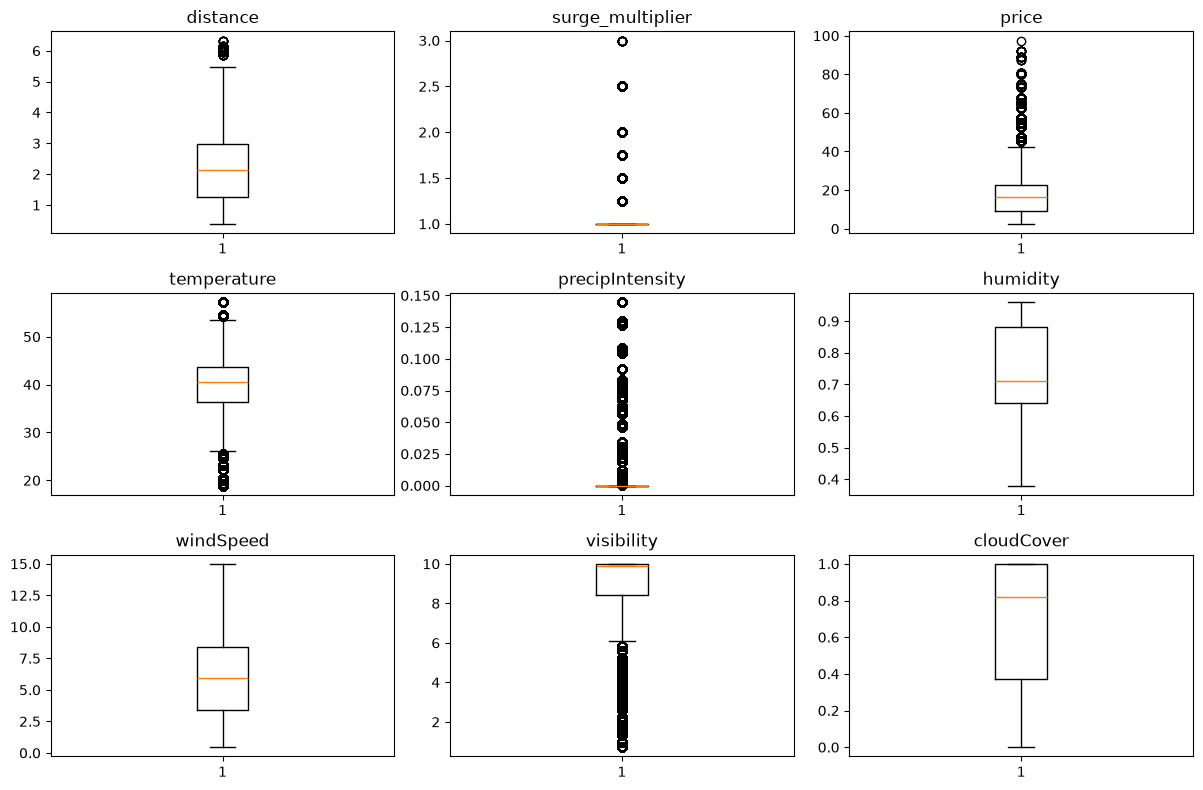

In [12]:
numeric_columns = ["distance", "surge_multiplier", "price", "temperature", "precipIntensity",
                   "humidity", "windSpeed", "visibility", "cloudCover"]

fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, col in zip(axes.ravel(), numeric_columns):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
plt.tight_layout()
plt.savefig("reports/figures/02_boxplots.png", dpi=100)
plt.show()

In [13]:
from src.outliers import iqr_report
report = iqr_report(df, numeric_columns)
display(report[["flagged", "flagged_%", "lower_fence", "upper_fence", "min", "max", "share_of_zeros_%", "share_at_max_%"]].round(3))
report.round(4).to_csv("reports/outlier_iqr_report.csv")

,flagged,flagged_%,lower_fence,upper_fence,min,max,share_of_zeros_%,share_at_max_%
column,,,,,,,,
distance,102,0.033,-1.280,5.520,0.390,6.330,0.000,0.002
surge_multiplier,20975,6.827,1.000,1.000,1.000,3.000,0.000,0.004
price,4092,1.332,-11.250,42.750,2.500,97.500,0.000,0.000
temperature,16010,5.211,25.755,54.275,18.910,57.220,0.000,0.265
precipIntensity,66473,21.635,0.000,0.000,0.000,0.145,78.365,0.436
humidity,0,0.000,0.280,1.240,0.380,0.960,0.000,1.606
windSpeed,0,0.000,-4.090,15.910,0.450,15.000,0.000,0.293
visibility,60378,19.651,6.086,12.342,0.717,10.000,0.000,24.182
cloudCover,0,0.000,-0.575,1.945,0.000,1.000,5.722,38.551


**Decision: no outlier rows are removed.**
- `surge_multiplier`: Q1 = Q3 = 1.0, so IQR marks **every** surged ride as an outlier. Those rides are exactly what we
  want to predict, so they are kept.
- `distance`: the maximum is 6.33 miles. That is a plausible trip inside Boston.
- `precipIntensity` is **zero-inflated**: most hours have no rain, so Q1 = Q3 = 0 and IQR flags **every** rainy hour
  (about 21% of rows). Those are real rain measurements, not errors.
- `visibility` is **capped at 10 miles** by the weather API and is concentrated just below the cap (median 9.9; 24% of
  rows are exactly 10). Every reduced-visibility hour (fog, rain) therefore falls below the lower fence. These are
  real readings too.
- `temperature`: the flagged values are the coldest (down to 18.9 °F) and mildest (up to 57.2 °F) hours. Both are
  normal for Boston in late November and December.
- `price`: leakage column, not a feature.

All values are physically possible, and the impossible-value checks above found 0 rows.
Rows are **never** dropped by target value. As an extra check, notebook 06 tests **winsorizing** (clipping numeric
features at the 1/99 and 5/95 percentiles of each training fold, inside the Pipeline) and compares the CV RMSE with
and without it.

## 7. Remove redundant / constant columns
Removing these keeps the file smaller and easier for EDA. Full reasons are in `data_dictionary.md`.
`price` is kept **only** so the EDA can show the leakage. It is excluded from the features later.

In [14]:
drop_cols = [
    "timezone", "cab_type", "product_id", "visibility.1", "long_summary", "icon",
    "latitude", "longitude", "timestamp",
    "windGustTime", "temperatureHighTime", "temperatureLowTime", "apparentTemperatureHighTime",
    "apparentTemperatureLowTime", "sunriseTime", "sunsetTime", "uvIndexTime",
    "temperatureMinTime", "temperatureMaxTime", "apparentTemperatureMinTime", "apparentTemperatureMaxTime",
    "temperatureHigh", "temperatureLow", "apparentTemperatureHigh", "apparentTemperatureLow",
    "temperatureMin", "temperatureMax", "apparentTemperatureMin", "apparentTemperatureMax",
    "precipIntensityMax", "ozone", "moonPhase",
]
cols_before = df.shape[1]
df = df.drop(columns=drop_cols)
df = df.rename(columns={"datetime": "pickup_datetime"})
df = df.sort_values("pickup_datetime").reset_index(drop=True)
print(cols_before, "->", df.shape[1], "columns")
print(df.columns.tolist())

57 -> 25 columns
['id', 'hour', 'day', 'month', 'pickup_datetime', 'source', 'destination', 'name', 'price', 'distance', 'surge_multiplier', 'temperature', 'apparentTemperature', 'short_summary', 'precipIntensity', 'precipProbability', 'humidity', 'windSpeed', 'windGust', 'visibility', 'dewPoint', 'pressure', 'windBearing', 'cloudCover', 'uvIndex']


## 8. Save

In [15]:
df.to_csv("data/processed/uber_cleaned.csv", index=False)
print("Final Shape:", df.shape)

Final Shape: (307252, 25)


In [16]:
summary.update({"rows_after": len(df),
                "missing_after": int(df.isnull().sum().sum()),
                "duplicates_after": int(df.duplicated().sum()),
                "invalid_records": invalid_records})
display(pd.DataFrame(log, columns=["step", "rows_before", "rows_after", "reason"]))
print(summary)

,step,rows_before,rows_after,reason
0,Remove Uber rows (target not recorded),693071,307408,surge_multiplier constant 1.0 for all Uber rows
1,Drop rows with missing target,307408,307408,cannot train on missing target
2,Drop exact duplicate rows,307408,307408,identical records
3,Drop duplicates ignoring id,307408,307252,same quote stored twice under different ids
4,Drop impossible values,307252,307252,"distance<=0, surge<=0 or invalid datetime"


{'rows_before': 693071, 'missing_before': 55095, 'duplicates_before': 0, 'rows_after': 307252, 'missing_after': 0, 'duplicates_after': 0, 'invalid_records': 0}
